<a href="https://colab.research.google.com/github/prathik002/DataScience-Lab/blob/main/Program_21.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

First Five Rows:
   SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm      Species
0            5.1           3.5            1.4           0.2  Iris-setosa
1            4.9           3.0            1.4           0.2  Iris-setosa
2            4.7           3.2            1.3           0.2  Iris-setosa
3            4.6           3.1            1.5           0.2  Iris-setosa
4            5.0           3.6            1.4           0.2  Iris-setosa

Dataset Shape:
(150, 5)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   SepalLengthCm  150 non-null    float64
 1   SepalWidthCm   150 non-null    float64
 2   PetalLengthCm  150 non-null    float64
 3   PetalWidthCm   150 non-null    float64
 4   Species        150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB

Statistical Summary:
       Sepal

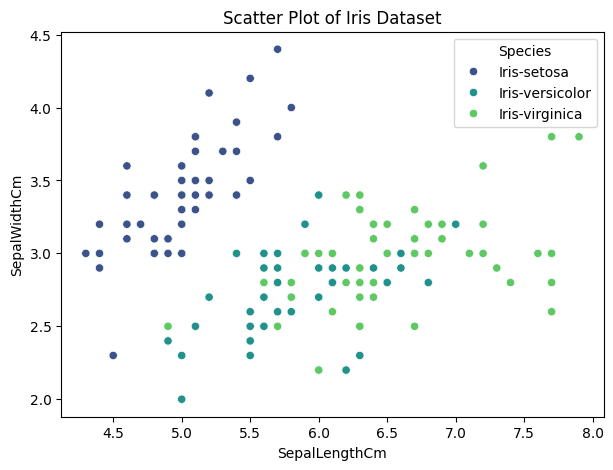


Cluster Labels:
[1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 0 0 2 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 2 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 2 0 2 2 2 2 0 2 2 2 2
 2 2 0 0 2 2 2 2 0 2 0 2 0 2 2 0 0 2 2 2 2 2 0 2 2 2 2 0 2 2 2 0 2 2 2 0 2
 2 0]

Cluster Centroids:
   SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm
0       5.901613      2.748387       4.393548      1.433871
1       5.006000      3.418000       1.464000      0.244000
2       6.850000      3.073684       5.742105      2.071053


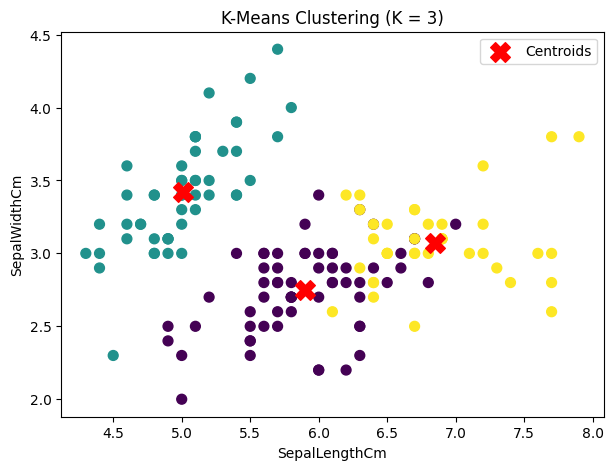


Number of Clusters: 3

Cluster Distribution:
Cluster
0    62
1    50
2    38
Name: count, dtype: int64


In [1]:
'''Program 21 : Implement the K-Means clustering algorithm using the
<Iris.csv> dataset
a) Conduct exploratory data analysis on the given dataset and report
the details.
b) Visualize the analysis results using (i) scatter plot (ii) histogram &
(iii) box plot.
c) Try with different K values and plot the elbow graph for the k
values.'''


import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans

# Step 1: Load the dataset
df = pd.read_csv("/content/Iris.csv")

# Remove unnecessary ID column, if present
if "Id" in df.columns:
    df = df.drop(columns=["Id"])

# Step 2: Exploratory Data Analysis (EDA)
print("First Five Rows:")
print(df.head())

print("\nDataset Shape:")
print(df.shape)

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
print(df.describe())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

# Step 3: Select numerical features
X = df.select_dtypes(include="number")

# Handle missing numerical values
X = X.fillna(X.mean())

# Step 4: Scatter Plot of Original Data
plt.figure(figsize=(7, 5))

if "Species" in df.columns:
    sns.scatterplot(
        x=X.iloc[:, 0],
        y=X.iloc[:, 1],
        hue=df["Species"],
        palette="viridis"
    )
else:
    plt.scatter(X.iloc[:, 0], X.iloc[:, 1])

plt.xlabel(X.columns[0])
plt.ylabel(X.columns[1])
plt.title("Scatter Plot of Iris Dataset")
plt.show()

# Step 5: Apply K-Means with K = 3
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

df["Cluster"] = kmeans.fit_predict(X)

# Step 6: Display cluster labels and centroids
print("\nCluster Labels:")
print(df["Cluster"].values)

print("\nCluster Centroids:")
centroids = pd.DataFrame(
    kmeans.cluster_centers_,
    columns=X.columns
)
print(centroids)

# Step 7: Visualize the resulting clusters
plt.figure(figsize=(7, 5))

plt.scatter(
    X.iloc[:, 0],
    X.iloc[:, 1],
    c=df["Cluster"],
    cmap="viridis",
    s=50
)

plt.scatter(
    kmeans.cluster_centers_[:, 0],
    kmeans.cluster_centers_[:, 1],
    color="red",
    marker="X",
    s=200,
    label="Centroids"
)

plt.xlabel(X.columns[0])
plt.ylabel(X.columns[1])
plt.title("K-Means Clustering (K = 3)")
plt.legend()
plt.show()

print("\nNumber of Clusters:", kmeans.n_clusters)
print("\nCluster Distribution:")
print(df["Cluster"].value_counts().sort_index())
